In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from  sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [13]:
data = pd.read_csv('predict_energy_consumption.xls')


In [14]:
data

,temperature,humidity,wind_speed,solar_irradiance,energy_consumption
0,24.363503,31.107976,5.234114,705.432695,307.398145
1,38.767858,52.514057,4.939576,817.013257,412.444548
2,33.299849,72.376750,18.125092,325.421109,392.072418
3,29.966462,63.933493,4.990924,662.386690,119.254957
4,18.900466,68.393669,5.438995,614.571385,117.162261
...,...,...,...,...,...
995,17.289552,59.417309,17.305915,497.896331,453.828793
996,37.932839,77.396877,3.145464,400.961061,103.721455
997,18.420466,24.137481,6.195757,455.115084,197.529277
998,38.755934,23.423283,5.800911,576.946528,417.085421


In [15]:
X = data[['temperature', 'humidity', 'wind_speed', 'solar_irradiance']]
y = data['energy_consumption']

In [16]:
print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (1000, 4)
y shape: (1000,)


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [18]:
scaler=StandardScaler()
X_train =scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [19]:
model=Sequential([
    Dense(64,activation='relu',input_shape=(X_train.shape[1],)),
    Dense(32,activation='relu'),

    Dense(1)
])

C:\Users\himan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\core\dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [20]:
model.compile(optimizer='adam',loss='mse',metrics=['mae'])

In [21]:
history=model.fit(X_train,y_train,epochs=50,batch_size=32,validation_split=0.2,verbose=1)

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 90568.8359 - mae: 272.0944 - val_loss: 83899.8516 - val_mae: 259.4074
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 90174.2422 - mae: 271.3634 - val_loss: 83518.2500 - val_mae: 258.6608
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 89696.9609 - mae: 270.4949 - val_loss: 82986.5781 - val_mae: 257.6224
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 88995.0781 - mae: 269.1958 - val_loss: 82159.4766 - val_mae: 256.0030
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 87907.8672 - mae: 267.1778 - val_loss: 80897.8281 - val_mae: 253.5098
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 86267.8906 - mae: 264.0826 - val_loss: 79044.9531 - val_mae: 249.7961
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 83896.6797 - mae: 259.5955 - val_loss: 76438.7656 - val_mae: 244.4738
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 80660.5234 - mae: 253.2885 - val_loss: 7296

In [24]:
test_loss, test_mae = model.evaluate(X_test, y_test, verbose=1)
print(f"Test MAE: {test_mae:.2f}")


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 18062.1875 - mae: 115.7545  
Test MAE: 115.75


In [25]:
predictions=model.predict(X_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


<function matplotlib.pyplot.ylabel(ylabel: 'str', fontdict: 'dict[str, Any] | None' = None, labelpad: 'float | None' = None, *, loc: "Literal['bottom', 'center', 'top'] | None" = None, **kwargs) -> 'Text'>

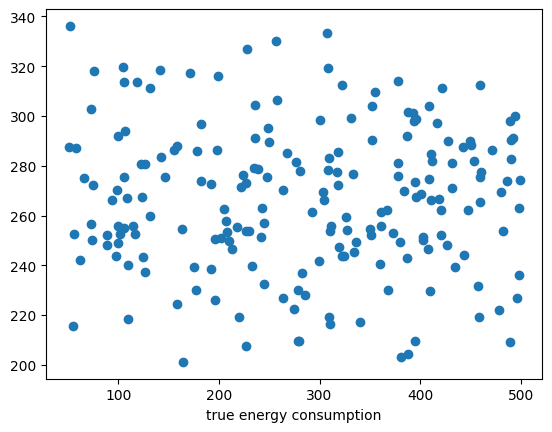

In [26]:
plt.scatter(y_test,predictions)
plt.xlabel('true energy consumption')
plt.ylabel

In [27]:
model=Sequential([
    Dense(128,activation='relu',input_shape=(X_train.shape[1],)),
    Dense(64,activation='relu'),
    Dense(32,activation='relu'),
    Dense(16,activation='relu'),
    Dense(1)

])

C:\Users\himan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\core\dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [28]:
model.compile(optimizer='adam',loss='mse',metrics=['mae'])

In [29]:
history=model.fit(X_train,y_train,epochs=50,batch_size=32,validation_split=0.2,verbose=1)

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 90300.1641 - mae: 271.6005 - val_loss: 83509.5938 - val_mae: 258.6578
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 89212.3438 - mae: 269.5862 - val_loss: 81533.1875 - val_mae: 254.8208
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 85114.5469 - mae: 261.8828 - val_loss: 74479.3594 - val_mae: 240.5866
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 72233.8516 - mae: 236.0006 - val_loss: 55498.0234 - val_mae: 197.6627
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 45865.9102 - mae: 175.8439 - val_loss: 26209.9648 - val_mae: 128.9912
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 21315.5781 - mae: 122.4990 - val_loss: 19605.1523 - val_mae: 119.5117
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 18355.1562 - mae: 116.6079 - val_loss: 18810.3535 - val_mae: 117.2624
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 17875.6797 - mae: 115.3939 - val_loss: 18733.

In [30]:
test_loss, test_mae = model.evaluate(X_test, y_test, verbose=1)
print(f"Test MAE: {test_mae:.2f}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 17607.3203 - mae: 114.0823  
Test MAE: 114.08


In [31]:
predictions=model.predict(X_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


<function matplotlib.pyplot.ylabel(ylabel: 'str', fontdict: 'dict[str, Any] | None' = None, labelpad: 'float | None' = None, *, loc: "Literal['bottom', 'center', 'top'] | None" = None, **kwargs) -> 'Text'>

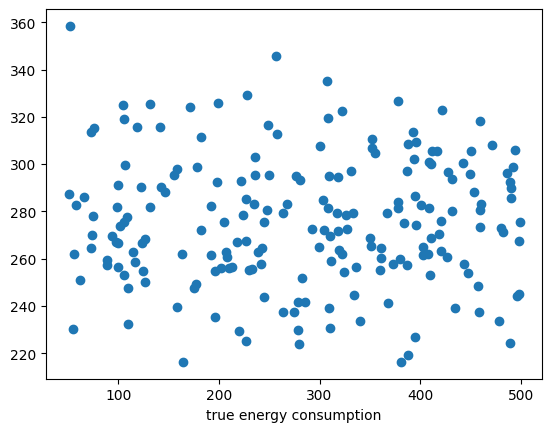

In [32]:
plt.scatter(y_test,predictions)
plt.xlabel('true energy consumption')
plt.ylabel

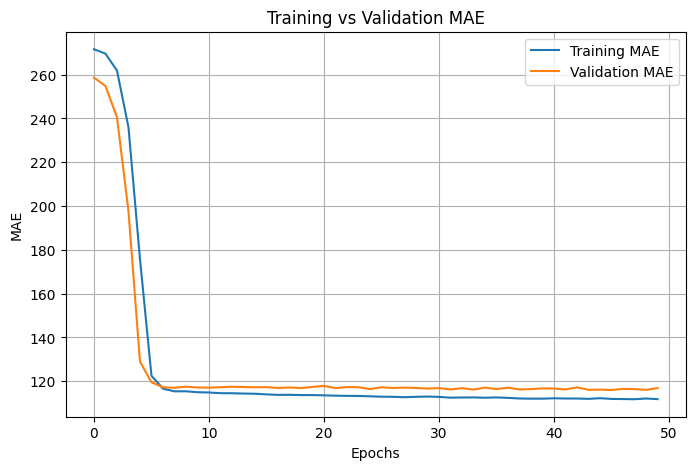

In [33]:
plt.figure(figsize=(8,5))
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.title('Training vs Validation MAE')
plt.legend()
plt.grid(True)
plt.show()